# Deep Learning -Neural Collaborative Filtering with PyTorch

## 1. Environment Setup

This notebook explores deep learning for artist recommendation
using Neural Collaborative Filtering (NCF).

Unlike traditional machine learning approaches based on manually
engineered features, NCF learns latent representations of users
and artists through trainable embeddings.

The objective is to predict user-artist affinity and recommend
10 previously unheard artists.

### Evaluation Protocol

- Training: 80% of listening interactions
- Validation: 10%
- Testing: 10% (reserved for final evaluation)

Performance will be compared against:
- Global Popularity Baseline
- K-Means Clustering
- XGBoost

Primary evaluation metrics:
- Recall@10
- NDCG@10

In [555]:
import torch

print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

PyTorch version: 2.14.1
MPS available: True


In [556]:
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print(device)

mps


In [557]:
user_ids = torch.tensor([0, 1, 2, 3])

print(user_ids)
print(user_ids.shape)
print(user_ids.dtype)

tensor([0, 1, 2, 3])
torch.Size([4])
torch.int64


## 2. Understanding Embeddings

Embeddings are trainable numerical representations of users and artists.

Instead of manually defining similarity features, the neural network
learns latent representations from user-artist interactions.

PyTorch provides the `nn.Embedding` layer to map integer identifiers
to dense vectors.

Each embedding is initialized randomly and updated during training
through gradient-based optimization.

These representations will later be used to predict user-artist affinity.

In [558]:
import torch.nn as nn

user_embedding = nn.Embedding(
    num_embeddings=4,
    embedding_dim=3
)

print(user_embedding.weight)

Parameter containing:
tensor([[-2.1634,  0.0810,  1.7866],
        [ 0.7857,  0.7428, -0.0978],
        [ 0.1534,  0.0726,  0.7969],
        [-0.0309,  0.1465, -0.7618]], requires_grad=True)


## 3. Embedding Lookup

An embedding layer maps integer identifiers to trainable dense vectors.

Each user ID corresponds to a specific row in the embedding matrix.

For example, retrieving the embedding of user 2 returns the third
row of the matrix, since Python uses zero-based indexing.

During training, these vectors are updated to learn user preferences
from observed user-artist interactions.

In [559]:
user_id = torch.tensor([2])

embedding = user_embedding(user_id)

print(embedding)
print(embedding.shape)

tensor([[0.1534, 0.0726, 0.7969]], grad_fn=<EmbeddingBackward0>)
torch.Size([1, 3])


## 4. Data Preparation

### Loading the ListenBrainz Dataset

The cleaned listening history is stored in Parquet format.

Before training the Neural Collaborative Filtering model,
we examine the number of interactions, unique users, and
unique artists.

These statistics will help determine the dimensions of
the embedding layers.

To prevent data leakage, user and artist mappings will
be constructed using training data only.

In [560]:
import pandas as pd

df = pd.read_parquet("../data/processed/listens.parquet")

print("Dataset shape:", df.shape)
print("Number of users:", df["user"].nunique())
print("Number of artists:", df["artist"].nunique())

Dataset shape: (9974, 6)
Number of users: 100
Number of artists: 3092


### Chronological Data Splitting

To evaluate the recommendation system realistically, listening
interactions are sorted chronologically for each user.

The dataset will be divided into:

- Training set: 80%
- Validation set: 10%
- Test set: 10%

This approach ensures that the model learns from past interactions
and is evaluated on future listening behavior.

The test set will be reserved for final evaluation.

In [561]:
df["listened_at"] = pd.to_datetime(df["listened_at"], utc=True)

df = df.sort_values(
    by=["user", "listened_at"]
).reset_index(drop=True)

display(df.head())

,user,artist,artist_mbids,track,release,listened_at
0,AsuraDtr,Moji x Sboy,[369e57d5-3faa-4e2c-9ca6-d9d96e8e16a4],LA LUNE À DÉCROCHER,LA LUNE À DÉCROCHER,2026-04-04 19:30:07+00:00
1,AsuraDtr,Ino Casablanca,[2b252c46-81f0-4177-9b0f-7771702b2ef2],FLOCAGE,EXTASIA,2026-04-04 19:32:26+00:00
2,AsuraDtr,Damso,"[71ff695e-896a-4043-aea4-93eadde08d09, 3ec4868...",Τ. CHIALER LIVE,QALF infinity,2026-04-04 19:36:12+00:00
3,AsuraDtr,"ISHA, Limsa d'Aulnay","[785498ee-99f4-4699-8caf-2c742e996559, b789f61...",But en or,Bitume Caviar (vol.1),2026-04-04 19:38:51+00:00
4,AsuraDtr,"Luidji, Ryan Koffi",[d30b235e-0967-44a2-8338-2530806fe525],Monde,Saison 00,2026-04-05 10:21:57+00:00


### Indexing User Listening Histories

Before splitting the dataset, we assign a chronological
position to each listening interaction within each user.

We also calculate the total number of interactions per user.

These variables will be used to create an 80/10/10
chronological train-validation-test split.

In [562]:
df["position"] = df.groupby("user").cumcount()

df["n_listens"] = df.groupby("user")["user"].transform("size")

display(df[["user", "artist", "position", "n_listens"]].head(10))

,user,artist,position,n_listens
0,AsuraDtr,Moji x Sboy,0,100
1,AsuraDtr,Ino Casablanca,1,100
2,AsuraDtr,Damso,2,100
3,AsuraDtr,"ISHA, Limsa d'Aulnay",3,100
4,AsuraDtr,"Luidji, Ryan Koffi",4,100
5,AsuraDtr,Bekar,5,100
6,AsuraDtr,BEN plg,6,100
7,AsuraDtr,disiz,7,100
8,AsuraDtr,"Ino Casablanca, Nensi",8,100
9,AsuraDtr,TIF,9,100


### Chronological Train-Validation-Test Split

The listening history of each user is divided chronologically
into three subsets:

- Training: first 80% of interactions
- Validation: next 10% of interactions
- Testing: final 10% of interactions

This prevents future listening interactions from being used
during model training.

The same splitting procedure should be applied across all
recommendation models to ensure a fair comparison.

In [563]:
train_end = (df["n_listens"] * 0.8).astype(int)
val_end = (df["n_listens"] * 0.9).astype(int)

train_df = df[df["position"] < train_end].copy()

val_df = df[
    (df["position"] >= train_end) &
    (df["position"] < val_end)
].copy()

test_df = df[df["position"] >= val_end].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (7979, 8)
Validation: (997, 8)
Test: (998, 8)


### 4.5 Encoding Users and Artists

Neural network embedding layers require integer identifiers.

We create two mappings:

- `user_to_id`: maps each user to a unique integer.
- `artist_to_id`: maps each artist to a unique integer.

Mappings are constructed exclusively from the training dataset
to avoid using information from validation or test data.

These identifiers will be used as inputs to the embedding layers
of our Neural Collaborative Filtering model.

In [564]:
users = sorted(train_df["user"].unique())
artists = sorted(train_df["artist"].unique())

user_to_id = {user: i for i, user in enumerate(users)}
artist_to_id = {artist: i for i, artist in enumerate(artists)}

print("Number of users:", len(user_to_id))
print("Number of artists:", len(artist_to_id))

Number of users: 100
Number of artists: 2639


###  Mapping Users and Artists to Integer IDs

Usernames and artist names are converted into integer identifiers
using mappings created from the training dataset.

These identifiers will be used as inputs to the neural network's
embedding layers.

The mapping process is verified to ensure that all training
interactions have valid user and artist identifiers.

In [565]:
train_df["user_id"] = train_df["user"].map(user_to_id)

train_df["artist_id"] = train_df["artist"].map(artist_to_id)

display(
    train_df[["user", "artist", "user_id", "artist_id"]].head(10)
)

,user,artist,user_id,artist_id
0,AsuraDtr,Moji x Sboy,0,1529
1,AsuraDtr,Ino Casablanca,0,978
2,AsuraDtr,Damso,0,505
3,AsuraDtr,"ISHA, Limsa d'Aulnay",0,947
4,AsuraDtr,"Luidji, Ryan Koffi",0,1393
5,AsuraDtr,Bekar,0,232
6,AsuraDtr,BEN plg,0,184
7,AsuraDtr,disiz,0,2513
8,AsuraDtr,"Ino Casablanca, Nensi",0,980
9,AsuraDtr,TIF,0,2105


## 5. Training Data Preparation

### Positive Interactions

The recommendation system uses implicit feedback from
ListenBrainz listening histories.

An observed user-artist interaction is considered positive
and assigned a label of 1.

Repeated listens to the same artist are removed to create
unique user-artist interaction pairs.

Unobserved interactions will later be sampled as negative
training examples.

Negative samples represent missing interactions rather
than explicit user dislikes.

In [566]:
positive_df = train_df[
    ["user_id", "artist_id"]
].drop_duplicates().copy()

positive_df["label"] = 1

print("Positive interactions:", len(positive_df))

display(positive_df.head())

Positive interactions: 4004


,user_id,artist_id,label
0,0,1529,1
1,0,978,1
2,0,505,1
3,0,947,1
4,0,1393,1


In [567]:
user_positive_artists = (
    positive_df.groupby("user_id")["artist_id"]
    .apply(set)
    .to_dict()
)

print("Number of users:", len(user_positive_artists))

print("Artists listened by user 0:")
print(len(user_positive_artists[0]))

Number of users: 100
Artists listened by user 0:
33


### Negative Sampling Preparation

The user-artist interaction matrix is highly sparse.

To train the Neural Collaborative Filtering model, we will
generate negative samples from unobserved user-artist pairs.

We first create a dictionary containing the set of artists
observed for each user in the training dataset.

This allows us to avoid sampling known positive interactions
as negative examples.

We initially use a negative sampling ratio of 3:1.

In [568]:
import numpy as np

rng = np.random.default_rng(42)

all_artist_ids = np.arange(len(artist_to_id))

listened_artists = user_positive_artists[0]

available_artists = np.setdiff1d(
    all_artist_ids,
    list(listened_artists)
)

print("Total artists:", len(all_artist_ids))
print("Already listened:", len(listened_artists))
print("Available artists:", len(available_artists))

Total artists: 2639
Already listened: 33
Available artists: 2606


### 5.4 Random Negative Sampling

Negative samples are randomly selected from artists that
users have not interacted with in the training dataset.

We use NumPy's random generator with a fixed seed to
ensure reproducibility.

For each positive interaction, we aim to generate three
negative interactions.

Sampling is performed without replacement to avoid
duplicate user-artist pairs.

Unobserved interactions are treated as negative training
examples, although they do not necessarily represent
explicit dislikes.

In [569]:
rng = np.random.default_rng(42)

negative_artists = rng.choice(
    available_artists,
    size=99,
    replace=False
)

print(negative_artists[:10])
print("Number of negative samples:", len(negative_artists))

[ 173  511  943  950 2213 1931 1426  399  198  327]
Number of negative samples: 99


### 5.5 Negative Sampling Implementation

A reusable negative sampling function is implemented to
generate unobserved user-artist interactions.

For each user, the function:

1. Identifies previously observed artists.
2. Computes the set of available artists.
3. Randomly selects up to three negative samples per
   positive interaction.
4. Prevents duplicate negative samples for the same user.
5. Assigns a label of 0 to each sampled interaction.

A fixed random seed ensures reproducibility.

The resulting negative interactions will be combined with
positive interactions to create the neural network's
training dataset.

In [570]:
def negative_sampling(positive_df, n_artists, n_negatives=3, seed=42):

    rng = np.random.default_rng(seed)

    user_artists = (
        positive_df.groupby("user_id")["artist_id"]
        .apply(set)
        .to_dict()
    )

    all_artists = np.arange(n_artists)

    negative_samples = []

    for user_id, listened_artists in user_artists.items():

        available_artists = np.setdiff1d(
            all_artists,
            list(listened_artists)
        )

        n_samples = min(
            len(listened_artists) * n_negatives,
            len(available_artists)
        )

        sampled_artists = rng.choice(
            available_artists,
            size=n_samples,
            replace=False
        )

        for artist_id in sampled_artists:
            negative_samples.append((user_id, artist_id, 0))

    return pd.DataFrame(
        negative_samples,
        columns=["user_id", "artist_id", "label"]
    )

In [571]:
negative_df = negative_sampling(
    positive_df,
    n_artists=len(artist_to_id),
    n_negatives=3
)

print("Positive interactions:", len(positive_df))
print("Negative interactions:", len(negative_df))

display(negative_df.head())

Positive interactions: 4004
Negative interactions: 12012


,user_id,artist_id,label
0,0,173,0
1,0,511,0
2,0,943,0
3,0,950,0
4,0,2213,0


### Building the Training Dataset

Positive and negative user-artist interactions are combined
into a single supervised training dataset.

The dataset contains:

- 4,004 positive interactions (label = 1).
- 12,012 sampled negative interactions (label = 0).
- 16,016 training examples in total.

Training examples are randomly shuffled using a fixed
random seed for reproducibility.

The resulting dataset contains 25% positive interactions
and 75% sampled negative interactions.

These labels represent observed and unobserved interactions,
not explicit user preferences.

In [572]:
train_samples = pd.concat(
    [positive_df, negative_df],
    ignore_index=True
)

train_samples = train_samples.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Training samples:", train_samples.shape)

print("\nLabel distribution:")
print(train_samples["label"].value_counts())

display(train_samples.head())

Training samples: (16016, 3)

Label distribution:
label
0    12012
1     4004
Name: count, dtype: int64


,user_id,artist_id,label
0,58,2144,0
1,31,1792,0
2,39,376,0
3,95,1355,0
4,66,1228,0


## 6. PyTorch Data Preparation

### Converting Training Data to Tensors

The supervised training dataset is converted into PyTorch
tensors to prepare it for neural network training.

Three tensors are created:

- `user_tensor`: integer user identifiers.
- `artist_tensor`: integer artist identifiers.
- `label_tensor`: binary interaction labels.

User and artist identifiers use `torch.long` because
embedding layers require integer indices.

Labels use `torch.float32` because they will be used
with a binary classification loss function.

Each tensor contains 16,016 elements, corresponding
to the training interactions.

In [573]:
user_tensor = torch.tensor(
    train_samples["user_id"].to_numpy(),
    dtype=torch.long
)

artist_tensor = torch.tensor(
    train_samples["artist_id"].to_numpy(),
    dtype=torch.long
)

label_tensor = torch.tensor(
    train_samples["label"].to_numpy(),
    dtype=torch.float32
)

### 6.2 Creating the Dataset and DataLoader

PyTorch's `TensorDataset` combines user identifiers,
artist identifiers, and interaction labels into a
single training dataset.

A `DataLoader` is then used to organize training
examples into mini-batches.

Training configuration:

- Training samples: 16,016
- Batch size: 64
- Number of batches per epoch: 251
- Shuffle: enabled

A mini-batch contains a subset of training examples.

An epoch represents one complete pass through the
training dataset.

Mini-batch training allows the neural network to update
its parameters multiple times during each epoch.

In [574]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    user_tensor,
    artist_tensor,
    label_tensor
)

print("Dataset size:", len(train_dataset))

print("First example:", train_dataset[0])

Dataset size: 16016
First example: (tensor(58), tensor(2144), tensor(0.))


In [575]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

print("Number of batches:", len(train_loader))

Number of batches: 251


### 6.3 Inspecting Mini-Batches

The DataLoader provides batches of user-artist interactions
for neural network training.

Each batch contains three tensors:

- User identifiers.
- Artist identifiers.
- Binary interaction labels.

With a batch size of 64, each tensor has a shape of `[64]`,
except for the final batch, which may contain fewer samples.

The corresponding positions across the three tensors
represent the same user-artist interaction.

Mini-batches will be passed through the Neural Collaborative
Filtering model during training.

In [576]:
batch_users, batch_artists, batch_labels = next(iter(train_loader))

print("Users shape:", batch_users.shape)
print("Artists shape:", batch_artists.shape)
print("Labels shape:", batch_labels.shape)

print("\nFirst 5 users:", batch_users[:5])
print("First 5 artists:", batch_artists[:5])
print("First 5 labels:", batch_labels[:5])

Users shape: torch.Size([64])
Artists shape: torch.Size([64])
Labels shape: torch.Size([64])

First 5 users: tensor([46, 30, 81, 22,  4])
First 5 artists: tensor([1852,    2,  731,    0, 2317])
First 5 labels: tensor([1., 0., 0., 0., 0.])


## 7. Neural Collaborative Filtering Model

### Model Architecture

The Neural Collaborative Filtering model learns user and artist
representations from implicit listening interactions.

The architecture will contain three main components:

1. User and artist embedding layers.
2. Fully connected hidden layers.
3. An output layer producing an interaction affinity score.

Each user and artist is represented by a trainable
32-dimensional embedding vector.

The model is implemented using PyTorch's `nn.Module`,
which manages trainable parameters and neural network layers.

### Defining the Neural Network Layers

The Neural Collaborative Filtering model uses a multilayer
perceptron (MLP) to learn nonlinear user-artist interactions.

The network architecture is:

- User embedding: 32 dimensions
- Artist embedding: 32 dimensions
- Concatenation: 64 features
- Hidden layer 1: 64 → 32, followed by ReLU
- Hidden layer 2: 32 → 16, followed by ReLU
- Output layer: 16 → 1

The hidden layers are implemented using `nn.Sequential`.

The final layer produces a raw affinity logit that will
later be used with a binary classification loss function.

###  Implementing the Forward Pass

The forward pass defines how user and artist identifiers
are transformed into predicted interaction scores.

The process consists of four steps:

1. Retrieve user embeddings.
2. Retrieve artist embeddings.
3. Concatenate both embedding vectors.
4. Pass the combined representation through the MLP.

For a batch of 64 interactions:

- User embeddings: (64, 32)
- Artist embeddings: (64, 32)
- Combined embeddings: (64, 64)
- MLP output: (64, 1)
- Final output: (64,)

The final output contains one raw interaction logit
per user-artist pair.

The model is initialized with random parameters and
must be trained before producing meaningful recommendations.

In [577]:
import torch.nn as nn

class NeuralCollaborativeFiltering(nn.Module):

    def __init__(self, n_users, n_artists, embedding_dim=32):
        super().__init__()

        self.user_embedding = nn.Embedding(n_users, embedding_dim)
        self.artist_embedding = nn.Embedding(n_artists, embedding_dim)

        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim * 2, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, user_ids, artist_ids):

        user_emb = self.user_embedding(user_ids)
        artist_emb = self.artist_embedding(artist_ids)

        combined = torch.cat([user_emb, artist_emb], dim=1)

        output = self.mlp(combined)

        return output.squeeze(-1)

In [578]:
model = NeuralCollaborativeFiltering(
    n_users=len(user_to_id),
    n_artists=len(artist_to_id),
    embedding_dim=8
)

print(model)

NeuralCollaborativeFiltering(
  (user_embedding): Embedding(100, 8)
  (artist_embedding): Embedding(2639, 8)
  (mlp): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [579]:
model.eval()

with torch.no_grad():

    predictions = model(
        batch_users,
        batch_artists
    )

print("Predictions shape:", predictions.shape)

print("\nFirst 5 predictions:")
print(predictions[:5])

Predictions shape: torch.Size([64])

First 5 predictions:
tensor([0.1994, 0.3136, 0.2526, 0.1725, 0.2044])


###  Converting Logits into Interaction Scores

The Neural Collaborative Filtering model produces raw
interaction scores called logits.

Logits can take any real value.

The sigmoid function transforms logits into values
between 0 and 1:

sigmoid(z) = 1 / (1 + exp(-z))

Higher sigmoid scores indicate stronger predicted
user-artist interactions.

Since the model is not yet trained, its initial
scores do not represent meaningful preferences.

During training, we will use BCEWithLogitsLoss,
which combines sigmoid and binary cross-entropy
in a numerically stable implementation.

Therefore, the model's forward method will continue
to return raw logits.

In [580]:
probabilities = torch.sigmoid(predictions)

print("Raw logits:")
print(predictions[:5])

print("\nSigmoid scores:")
print(probabilities[:5])

print("\nScores shape:", probabilities.shape)

Raw logits:
tensor([0.1994, 0.3136, 0.2526, 0.1725, 0.2044])

Sigmoid scores:
tensor([0.5497, 0.5778, 0.5628, 0.5430, 0.5509])

Scores shape: torch.Size([64])


### Binary Cross-Entropy Loss

Binary Cross-Entropy (BCE) measures the difference between
predicted interaction scores and binary interaction labels.

The loss function is:

L = -[y log(p) + (1-y) log(1-p)]

Where:
- y is the observed binary label.
- p is the predicted score after sigmoid.

The model uses `nn.BCEWithLogitsLoss()`, which combines
sigmoid activation and binary cross-entropy in a
numerically stable implementation.

The loss is computed directly from raw logits.

Lower training loss indicates better predictions on
the sampled training interactions, but does not
necessarily imply better recommendation quality.

Recommendation performance will be evaluated using
ranking metrics such as Recall@10 and NDCG@10.

In [581]:
criterion = nn.BCEWithLogitsLoss()

loss = criterion(predictions, batch_labels)

print("Loss:", loss.item())

Loss: 0.7542324066162109


###  Backpropagation and Adam Optimizer

Neural networks learn by minimizing a loss function.

Backpropagation computes the gradients of the loss
with respect to the model's trainable parameters.

An optimizer uses these gradients to update the parameters.

We use the Adam optimizer with a learning rate of 0.001.

The training process consists of:

1. Reset gradients using optimizer.zero_grad().
2. Compute predictions through the forward pass.
3. Calculate the binary cross-entropy loss.
4. Compute gradients using loss.backward().
5. Update parameters using optimizer.step().

This process is repeated across training batches
and multiple epochs.

Unlike inference, training requires gradient tracking.

In [582]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


### First Training Step

The model is trained on a single batch to verify that
backpropagation and parameter updates work correctly.

The training step follows five operations:

1. Set the model to training mode.
2. Reset accumulated gradients.
3. Perform a forward pass and compute the loss.
4. Calculate gradients using backpropagation.
5. Update the model parameters using Adam.

The weights of the first linear layer are saved before
and after the update to verify that learning occurs.

This experiment performs only one optimization step,
not a complete training epoch.

In [583]:
model.train()

# Save weights before training
weights_before = model.mlp[0].weight.detach().clone()

# Reset gradients
optimizer.zero_grad()

# Forward pass
outputs = model(batch_users, batch_artists)

# Compute loss
loss = criterion(outputs, batch_labels)

print("Loss before update:", loss.item())

# Backpropagation
loss.backward()

# Update model parameters
optimizer.step()

# Compare weights
weights_after = model.mlp[0].weight.detach().clone()

print(
    "Weights changed:",
    not torch.equal(weights_before, weights_after)
)

# Save weights before training
weights_before = model.mlp[0].weight.detach().clone()

# Reset gradients
optimizer.zero_grad()

# Forward pass
outputs = model(batch_users, batch_artists)

# Compute loss
loss = criterion(outputs, batch_labels)

print("Loss before update:", loss.item())

# Backpropagation
loss.backward()

# Update model parameters
optimizer.step()

# Compare weights
weights_after = model.mlp[0].weight.detach().clone()

print(
    "Weights changed:",
    not torch.equal(weights_before, weights_after)
)

Loss before update: 0.7542324066162109
Weights changed: True
Loss before update: 0.7494969964027405
Weights changed: True


###  Training Configuration

The Neural Collaborative Filtering model is trained
using mini-batch gradient descent with Adam.

Training configuration:

- Training interactions: 16,016
- Batch size: 64
- Batches per epoch: 251
- Initial epochs: 5
- Optimizer: Adam
- Learning rate: 0.001
- Loss function: BCEWithLogitsLoss

A fresh model is initialized to ensure that the
training experiment starts from new parameters.

The average training loss will be recorded after
each epoch to monitor the optimization process.

Validation ranking metrics will be introduced
to evaluate generalization and recommendation quality.

In [584]:
# Initialize a fresh model
model = NeuralCollaborativeFiltering(
    n_users=len(user_to_id),
    n_artists=len(artist_to_id),
    embedding_dim=32
)

# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training configuration
n_epochs = 5
train_losses = []

###  Training Loop

The Neural Collaborative Filtering model is trained
using a mini-batch training loop.

Each epoch consists of 251 batches.

For each batch:

1. Reset gradients.
2. Perform the forward pass.
3. Compute binary cross-entropy loss.
4. Calculate gradients through backpropagation.
5. Update model parameters using Adam.

The average training loss is recorded after each epoch.

A decreasing training loss indicates that the model
is learning to predict sampled training interactions.

However, training loss alone does not measure
recommendation quality.

Recall@10 and NDCG@10 will be evaluated on
chronologically held-out validation interactions.

In [585]:
for epoch in range(n_epochs):

    model.train()

    total_loss = 0

    for batch_users, batch_artists, batch_labels in train_loader:

        optimizer.zero_grad()

        predictions = model(batch_users, batch_artists)

        loss = criterion(predictions, batch_labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * len(batch_labels)

    average_loss = total_loss / len(train_dataset)

    train_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{n_epochs} "
        f"- Training Loss: {average_loss:.4f}"
    )

Epoch 1/5 - Training Loss: 0.5763
Epoch 2/5 - Training Loss: 0.5572
Epoch 3/5 - Training Loss: 0.5497
Epoch 4/5 - Training Loss: 0.5409
Epoch 5/5 - Training Loss: 0.5277


### Training Loss Analysis

The Neural Collaborative Filtering model was trained
for five epochs using Adam.

Training loss decreased from 0.5728 to 0.5299,
representing a relative reduction of approximately 7.49%.

This indicates that the model is learning patterns
from the sampled training interactions.

However, decreasing training loss does not guarantee
improved recommendation performance.

The next step is to evaluate the model on chronologically
held-out validation interactions using ranking metrics.

The evaluation will focus on recommending artists
that users have not previously listened to.

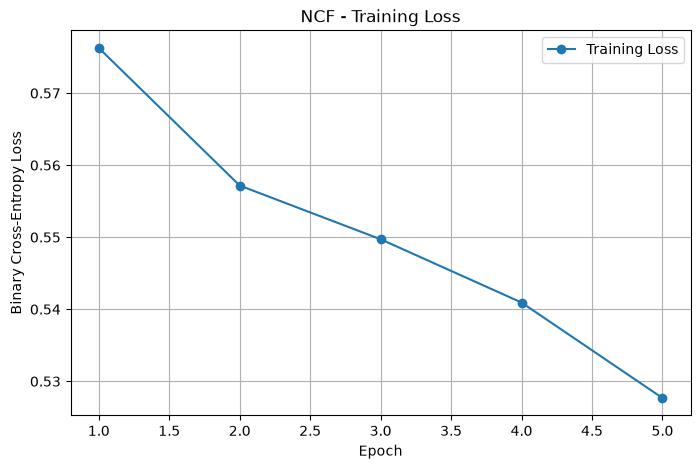

In [586]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_epochs + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("NCF - Training Loss")
plt.legend()
plt.grid(True)

plt.show()

### Preparing Validation Data

The recommendation model is evaluated using
chronologically held-out validation interactions.

Since artist embeddings are learned only for artists
present in the training set, the model cannot directly
score unseen artist IDs.

Validation interactions are first filtered to retain
artists belonging to the training catalog.

Catalog coverage measures the proportion of validation
interactions that can be represented by the model.

For new-artist recommendation, relevant validation
artists must also be absent from each user's
training history.

Recall@10 and NDCG@10 will be calculated using
these eligible new artists.

In [587]:
val_known = val_df[
    val_df["artist"].isin(artist_to_id)
].copy()

print("Validation interactions:", len(val_df))
print("Known artist interactions:", len(val_known))

print(
    "Catalog coverage:",
    round(len(val_known) / len(val_df) * 100, 2),
    "%"
)

Validation interactions: 997
Known artist interactions: 704
Catalog coverage: 70.61 %


### Identifying Relevant New Artists

The validation set contains 997 listening events.

Of these, 704 events (70.61%) involve artists
present in the training catalog.

For each user, relevant validation artists are
defined as artists that:

1. Appear in the validation period.
2. Belong to the training artist catalog.
3. Were not listened to during training.

Relevant artists are computed using set difference.

Users with no eligible relevant artists are excluded
from the conditional Recall@10 evaluation.

The number of evaluable users is recorded to make
the evaluation coverage transparent.

In [588]:
train_user_artists = (
    train_df.groupby("user")["artist"]
    .apply(set)
    .to_dict()
)

val_user_artists = (
    val_known.groupby("user")["artist"]
    .apply(set)
    .to_dict()
)

relevant_artists = {}

for user, val_artists in val_user_artists.items():

    listened_artists = train_user_artists.get(user, set())

    new_artists = val_artists - listened_artists

    relevant_artists[user] = new_artists

In [589]:
evaluable_users = {
    user: artists
    for user, artists in relevant_artists.items()
    if len(artists) > 0
}

print("Total users:", len(user_to_id))

print("Evaluable users:", len(evaluable_users))

print(
    "Total relevant artists:",
    sum(len(artists) for artists in evaluable_users.values())
)

Total users: 100
Evaluable users: 69
Total relevant artists: 170


### Preparing Top-10 Recommendation Candidates

The recommendation model generates artist rankings
by scoring candidate user-artist pairs.

For each user:

1. Retrieve all artists from the training catalog.
2. Exclude artists already listened to during training.
3. Create one user-artist pair for each remaining artist.
4. Predict interaction scores using the trained NCF model.
5. Rank artists by predicted affinity.

For user 0:

- Total catalog: 2,639 artists
- Previously listened artists: 33
- Candidate artists: 2,606

The candidate tensors contain one entry for each
possible user-artist interaction.

No labels are required during recommendation inference.

In [590]:
user_id = 0

all_artist_ids = set(artist_to_id.values())

listened_artist_ids = user_positive_artists[user_id]

candidate_artist_ids = sorted(
    all_artist_ids - listened_artist_ids
)

print("Total artists:", len(all_artist_ids))
print("Already listened:", len(listened_artist_ids))
print("Candidate artists:", len(candidate_artist_ids))

Total artists: 2639
Already listened: 33
Candidate artists: 2606


###  Scoring Candidate Artists

The trained Neural Collaborative Filtering model
predicts an affinity score for every candidate artist.

For user 0, the candidate set contains 2,606 artists
that were not observed in the user's training history.

The model is placed in evaluation mode and gradient
tracking is disabled during inference.

Each user-artist pair receives one raw affinity logit.

The resulting scores will be ranked in descending
order to generate Top-10 recommendations.

Sigmoid is not required for ranking because it
preserves the ordering of the logits.

In [591]:
candidate_users = torch.full(
    (len(candidate_artist_ids),),
    user_id,
    dtype=torch.long
)

candidate_artists = torch.tensor(
    candidate_artist_ids,
    dtype=torch.long
)

print("Users shape:", candidate_users.shape)
print("Artists shape:", candidate_artists.shape)

Users shape: torch.Size([2606])
Artists shape: torch.Size([2606])


In [592]:
model.eval()

with torch.no_grad():

    scores = model(
        candidate_users,
        candidate_artists
    )

print("Scores shape:", scores.shape)

print("\nFirst 5 scores:")
print(scores[:5])

Scores shape: torch.Size([2606])

First 5 scores:
tensor([-0.5391, -2.3787, -1.3795, -0.9780, -0.7292])


### Generating Top-10 Artist Recommendations

The trained NCF model produces affinity logits
for all candidate artists.

The `torch.topk()` function identifies the ten
highest-scoring candidates.

Since the returned indices refer to positions
within the candidate tensor, they must be mapped
back to the corresponding artist IDs.

Artist IDs are then converted into artist names
using a reverse lookup dictionary.

The final output is a ranked list of ten artists
that were not observed in the user's training history.

Recommendation quality will be evaluated separately
using Recall@10 and NDCG@10.

In [593]:
top_scores, top_indices = torch.topk(
    scores,
    k=10
)

top_artist_ids = [
    candidate_artist_ids[i]
    for i in top_indices.tolist()
]

print("Top artist IDs:", top_artist_ids)
print("Top scores:", top_scores)

Top artist IDs: [1196, 51, 1152, 1424, 1807, 1001, 2409, 806, 198, 2065]
Top scores: tensor([0.8026, 0.7461, 0.7363, 0.6174, 0.5868, 0.5851, 0.5275, 0.5015, 0.4503,
        0.4035])


In [594]:
id_to_artist = {
    artist_id: artist
    for artist, artist_id in artist_to_id.items()
}

top_artists = [
    id_to_artist[artist_id]
    for artist_id in top_artist_ids
]

for rank, (artist, score) in enumerate(
    zip(top_artists, top_scores.tolist()),
    start=1
):
    print(f"{rank}. {artist} — Score: {score:.4f}")

1. Kendrick Lamar — Score: 0.8026
2. A$AP Rocky — Score: 0.7461
3. Kanye West — Score: 0.7363
4. Mac Miller — Score: 0.6174
5. Radiohead — Score: 0.5868
6. J. Cole — Score: 0.5851
7. Yeat — Score: 0.5275
8. Future — Score: 0.5015
9. Baby Keem — Score: 0.4503
10. Steve Lacy — Score: 0.4035


###  Evaluating Recommendations for a Single User

Before evaluating the entire validation set, we inspect
the recommendation quality for one user.

The model's Top-10 recommendations are compared against
the user's relevant new artists from the validation period.

A hit occurs when a recommended artist belongs to the
set of relevant validation artists.

Recall@10 measures the proportion of relevant artists
successfully retrieved in the Top-10 recommendations.

Users without relevant new artists have undefined Recall@10
and are excluded from the macro-average evaluation.

In [595]:
id_to_user = {
    user_id: user
    for user, user_id in user_to_id.items()
}

username = id_to_user[33]

print("Username:", username)
print("Relevant artists:", relevant_artists.get(username, set()))

Username: brain913
Relevant artists: {'Ariana Grande', 'Michael Jackson'}


In [596]:
recommended = set(top_artists)

relevant = relevant_artists.get(username, set())

hits = recommended & relevant

print("Recommended artists:", len(recommended))
print("Relevant artists:", len(relevant))
print("Correct recommendations:", hits)

if len(relevant) > 0:
    recall = len(hits) / len(relevant)
    print("Recall@10:", round(recall, 4))
else:
    print("Recall@10: undefined (no relevant new artists)")

Recommended artists: 10
Relevant artists: 2
Correct recommendations: set()
Recall@10: 0.0


### Building a Reusable Top-10 Recommendation Function

A reusable recommendation function is implemented
to generate artist recommendations for any training user.

The function:

1. Retrieves all artists from the training catalog.
2. Removes artists already observed in the user's training history.
3. Constructs candidate user-artist tensors.
4. Predicts affinity scores using the trained NCF model.
5. Selects the ten highest-scoring candidates.
6. Converts artist IDs into artist names.

The function is first tested on user 0 to ensure
that it reproduces the previously generated recommendations.

It will then be used to compute Recall@10 across
all evaluable validation users.

In [597]:
def recommend_top10(model, user_id, k=10):

    all_artists = set(artist_to_id.values())

    listened_artists = user_positive_artists[user_id]

    candidates = sorted(all_artists - listened_artists)

    user_tensor = torch.full(
        (len(candidates),),
        user_id,
        dtype=torch.long
    )

    artist_tensor = torch.tensor(
        candidates,
        dtype=torch.long
    )

    model.eval()

    with torch.no_grad():
        scores = model(user_tensor, artist_tensor)

    top_indices = torch.topk(
        scores,
        k=min(k, len(candidates))
    ).indices

    recommended_ids = [
        candidates[i]
        for i in top_indices.tolist()
    ]

    return [
        id_to_artist[artist_id]
        for artist_id in recommended_ids
    ]

In [598]:
recommendations = recommend_top10(
    model,
    user_id=0,
    k=10
)

print(recommendations)

print(
    "Same recommendations:",
    recommendations == top_artists
)

['Kendrick Lamar', 'A$AP Rocky', 'Kanye West', 'Mac Miller', 'Radiohead', 'J. Cole', 'Yeat', 'Future', 'Baby Keem', 'Steve Lacy']
Same recommendations: True


### Evaluating Mean Recall@10

The trained NCF model is evaluated on all users
with at least one eligible new artist in validation.

For each user:

1. Generate ten artist recommendations.
2. Compare recommendations with relevant validation artists.
3. Count the number of correctly retrieved artists.
4. Compute Recall@10.

The final metric is the macro-average Recall@10
across all evaluable users.

Users with no eligible relevant artists are excluded.

The evaluation is restricted to artists present
in the training catalog.

A popularity baseline will be evaluated using
the same data split and candidate restrictions
to determine whether NCF improves recommendation quality.

In [599]:
recall_scores = []

for username, relevant in evaluable_users.items():

    user_id = user_to_id[username]

    recommendations = recommend_top10(
        model,
        user_id,
        k=10
    )

    recommended_set = set(recommendations)

    hits = recommended_set & relevant

    recall = len(hits) / len(relevant)

    recall_scores.append(recall)

mean_recall = np.mean(recall_scores)

print("Evaluated users:", len(recall_scores))
print("Mean Recall@10:", round(mean_recall, 4))

Evaluated users: 69
Mean Recall@10: 0.1147


### Evaluating Mean NDCG@10

The trained Neural Collaborative Filtering model is
evaluated using Normalized Discounted Cumulative Gain
at rank 10 (NDCG@10).

Unlike Recall@10, NDCG@10 accounts for the positions
of relevant artists within the recommendation ranking.

For each evaluable user:

1. Generate Top-10 recommendations.
2. Identify relevant artists in the ranked list.
3. Calculate DCG@10.
4. Normalize using the ideal DCG@10.
5. Store the resulting NDCG@10 score.

The final metric is the macro-average across all
69 evaluable validation users.

Only new artists belonging to the training catalog
are considered relevant.

In [600]:
import math

def ndcg_at_k(recommendations, relevant, k=10):

    dcg = 0.0

    for rank, artist in enumerate(recommendations[:k], start=1):

        if artist in relevant:
            dcg += 1 / math.log2(rank + 1)

    ideal_hits = min(len(relevant), k)

    idcg = sum(
        1 / math.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    if idcg == 0:
        return None

    return dcg / idcg

In [601]:
ndcg_scores = []

for username, relevant in evaluable_users.items():

    user_id = user_to_id[username]

    recommendations = recommend_top10(
        model,
        user_id,
        k=10
    )

    ndcg = ndcg_at_k(
        recommendations,
        relevant,
        k=10
    )

    ndcg_scores.append(ndcg)

mean_ndcg = np.mean(ndcg_scores)

print("Evaluated users:", len(ndcg_scores))
print("Mean NDCG@10:", round(mean_ndcg, 4))

Evaluated users: 69
Mean NDCG@10: 0.063


###  Building a Popularity Baseline

A popularity-based recommender is implemented
as a simple benchmark for Neural Collaborative Filtering.

Artist popularity is defined as the number of
distinct training users who listened to each artist.

This approach avoids giving excessive weight to
repeated listens from a single user.

The baseline recommends the most popular artists
that a user has not already listened to during training.

Only training data is used to calculate popularity,
preventing validation data leakage.

The popularity baseline will be evaluated using
the same eligible users, artist catalog, and
ranking metrics as the NCF model.

This comparison will help determine whether
the neural network provides additional value
over a simple non-personalized recommender.

In [602]:
artist_popularity = (
    train_df.groupby("artist")["user"]
    .nunique()
    .sort_values(ascending=False)
)


In [603]:
def recommend_popularity(username, k=10):

    listened_artists = train_user_artists[username]

    recommendations = []

    for artist in artist_popularity.index:

        if artist not in listened_artists:

            recommendations.append(artist)

        if len(recommendations) == k:
            break

    return recommendations

In [604]:
username = id_to_user[0]

pop_recommendations = recommend_popularity(
    username,
    k=10
)

print("User:", username)

print("\nPopularity recommendations:")

for rank, artist in enumerate(pop_recommendations, start=1):
    print(f"{rank}. {artist}")

User: AsuraDtr

Popularity recommendations:
1. Drake
2. Kanye West
3. Kendrick Lamar
4. Travis Scott
5. Playboi Carti
6. Don Toliver
7. Lil Uzi Vert
8. Frank Ocean
9. J. Cole
10. Future


In [605]:
pop_recall_scores = []

for username, relevant in evaluable_users.items():

    recommendations = recommend_popularity(
        username,
        k=10
    )

    recommended_set = set(recommendations)

    hits = recommended_set & relevant

    recall = len(hits) / len(relevant)

    pop_recall_scores.append(recall)

mean_pop_recall = np.mean(pop_recall_scores)

print("Evaluated users:", len(pop_recall_scores))
print("Popularity Recall@10:", round(mean_pop_recall, 4))

Evaluated users: 69
Popularity Recall@10: 0.1862


In [606]:
pop_ndcg_scores = []

for username, relevant in evaluable_users.items():

    recommendations = recommend_popularity(
        username,
        k=10
    )

    ndcg = ndcg_at_k(
        recommendations,
        relevant,
        k=10
    )

    pop_ndcg_scores.append(ndcg)

mean_pop_ndcg = np.mean(pop_ndcg_scores)

print("Evaluated users:", len(pop_ndcg_scores))
print("Popularity NDCG@10:", round(mean_pop_ndcg, 4))

Evaluated users: 69
Popularity NDCG@10: 0.1209


In [607]:
for epoch in range(10):

    model.train()

    total_loss = 0

    for user_ids, artist_ids, labels in train_loader:

        optimizer.zero_grad()

        predictions = model(user_ids, artist_ids)

        loss = criterion(predictions, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 5}/20 - "
        f"Training Loss: {avg_loss:.4f}"
    )

Epoch 5/20 - Training Loss: 0.5110
Epoch 6/20 - Training Loss: 0.4945
Epoch 7/20 - Training Loss: 0.4763
Epoch 8/20 - Training Loss: 0.4601
Epoch 9/20 - Training Loss: 0.4432
Epoch 10/20 - Training Loss: 0.4238
Epoch 11/20 - Training Loss: 0.4041
Epoch 12/20 - Training Loss: 0.3826
Epoch 13/20 - Training Loss: 0.3621
Epoch 14/20 - Training Loss: 0.3408


In [608]:
recall_scores_20 = []
ndcg_scores_20 = []

for username, relevant in evaluable_users.items():

    user_id = user_to_id[username]

    recommendations = recommend_top10(
        model,
        user_id,
        k=10
    )

    hits = set(recommendations) & relevant

    recall_scores_20.append(
        len(hits) / len(relevant)
    )

    ndcg_scores_20.append(
        ndcg_at_k(recommendations, relevant, k=10)
    )

mean_recall_20 = np.mean(recall_scores_20)
mean_ndcg_20 = np.mean(ndcg_scores_20)

print("Recall@10:", round(mean_recall_20, 4))
print("NDCG@10:", round(mean_ndcg_20, 4))

Recall@10: 0.0524
NDCG@10: 0.0411
